Importing Required Libraries

In [4]:
import os
import struct
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.stat import Correlation

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

Starting Spark

In [5]:
spark = SparkSession.builder \
    .appName("FashionMNIST_CNN") \
    .master("local[*]") \
    .getOrCreate()

spark

Define the dataset location

In [6]:
DATA_PATH = r"C:\Users\nxuma\Fashion-MNIST"

train_images_path = os.path.join(DATA_PATH, "train-images-idx3-ubyte")
train_labels_path = os.path.join(DATA_PATH, "train-labels-idx1-ubyte")

test_images_path = os.path.join(DATA_PATH, "t10k-images-idx3-ubyte")
test_labels_path = os.path.join(DATA_PATH, "t10k-labels-idx1-ubyte")

Reading the IDX image files

In [7]:
def read_idx_images(filename):
    with open(filename, "rb") as f:
        magic, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(
            f.read(),
            dtype=np.uint8
        ).reshape(num_images, rows, cols)
        
    return images


def read_idx_labels(filename):
    with open(filename, "rb") as f:
        magic, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(
            f.read(),
            dtype=np.uint8
        )
        
    return labels

Loading the datasets

In [8]:
X_train = read_idx_images(train_images_path)
y_train = read_idx_labels(train_labels_path)

X_test = read_idx_images(test_images_path)
y_test = read_idx_labels(test_labels_path)

Checking the dimensions

In [9]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


Creating a Spark DataFrame

In [10]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)

pixel_columns = [f"pixel_{i}" for i in range(784)]

train_pd = pd.DataFrame(
    X_train_flat,
    columns=pixel_columns
)

train_pd["label"] = y_train

In [11]:
train_spark = spark.createDataFrame(train_pd)

train_spark.printSchema()

root
 |-- pixel_0: long (nullable = true)
 |-- pixel_1: long (nullable = true)
 |-- pixel_2: long (nullable = true)
 |-- pixel_3: long (nullable = true)
 |-- pixel_4: long (nullable = true)
 |-- pixel_5: long (nullable = true)
 |-- pixel_6: long (nullable = true)
 |-- pixel_7: long (nullable = true)
 |-- pixel_8: long (nullable = true)
 |-- pixel_9: long (nullable = true)
 |-- pixel_10: long (nullable = true)
 |-- pixel_11: long (nullable = true)
 |-- pixel_12: long (nullable = true)
 |-- pixel_13: long (nullable = true)
 |-- pixel_14: long (nullable = true)
 |-- pixel_15: long (nullable = true)
 |-- pixel_16: long (nullable = true)
 |-- pixel_17: long (nullable = true)
 |-- pixel_18: long (nullable = true)
 |-- pixel_19: long (nullable = true)
 |-- pixel_20: long (nullable = true)
 |-- pixel_21: long (nullable = true)
 |-- pixel_22: long (nullable = true)
 |-- pixel_23: long (nullable = true)
 |-- pixel_24: long (nullable = true)
 |-- pixel_25: long (nullable = true)
 |-- pixel_26: lo

In [13]:
train_spark.show(5)

+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------

Checking missing values using Spark

In [14]:
missing_values = train_spark.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in train_spark.columns
])

missing_values.show()

+-------+-------+-------+-------+-------+-------+-------+-------+-------+-------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------

In [15]:
total_missing = train_spark.select(
    sum(
        F.col(c).isNull().cast("int")
        for c in train_spark.columns
    ).alias("total_missing")
)

total_missing.show()

+-------------+
|total_missing|
+-------------+
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
|            0|
+-------------+
only showing top 20 rows



Checking the class distribution using Spark

In [16]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [17]:
class_distribution = train_spark.groupBy("label") \
    .count() \
    .orderBy("label")

class_distribution.show()

+-----+-----+
|label|count|
+-----+-----+
|    0| 6000|
|    1| 6000|
|    2| 6000|
|    3| 6000|
|    4| 6000|
|    5| 6000|
|    6| 6000|
|    7| 6000|
|    8| 6000|
|    9| 6000|
+-----+-----+



Converting to Pandas for plotting

In [18]:
class_distribution_pd = class_distribution.toPandas()

class_distribution_pd["class_name"] = (
    class_distribution_pd["label"]
    .apply(lambda x: class_names[x])
)

class_distribution_pd

,label,count,class_name
0,0,6000,T-shirt/top
1,1,6000,Trouser
2,2,6000,Pullover
3,3,6000,Dress
4,4,6000,Coat
5,5,6000,Sandal
6,6,6000,Shirt
7,7,6000,Sneaker
8,8,6000,Bag
9,9,6000,Ankle boot


Bar - Plot

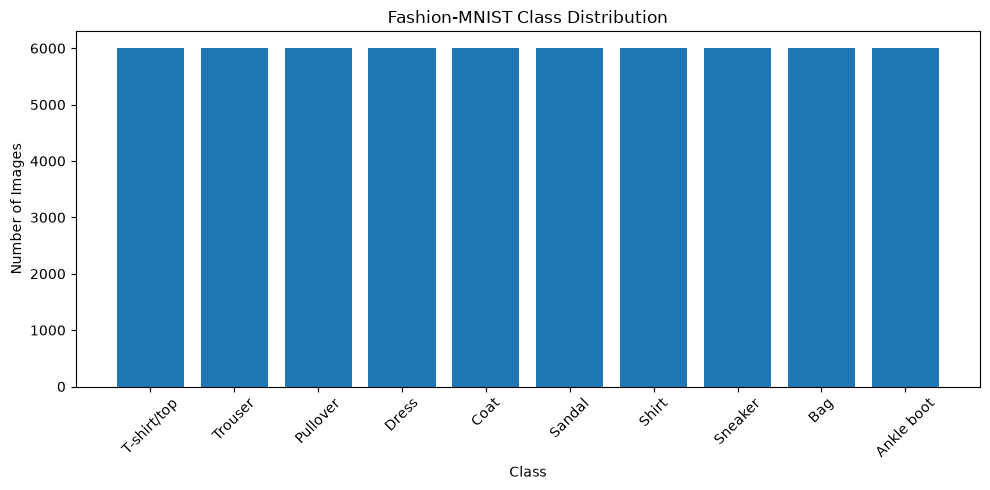

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_distribution_pd["class_name"],
    class_distribution_pd["count"]
)

plt.xticks(rotation=45)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Fashion-MNIST Class Distribution")

plt.tight_layout()
plt.show()

Display sample images

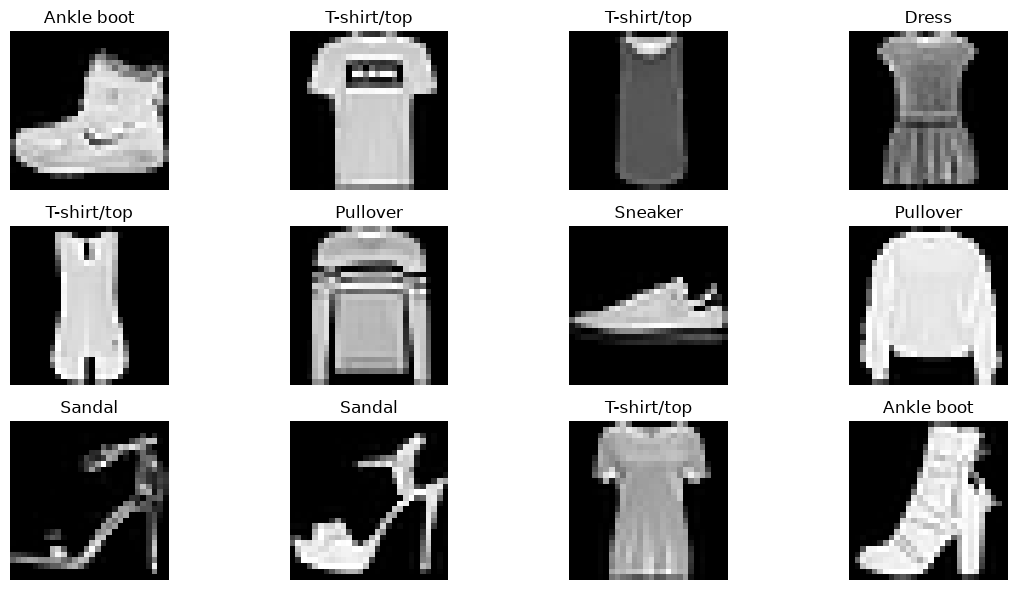

In [20]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Examining pixel statistics using Spark

Calculating the average pixel intensity.

In [21]:
pixel_means = train_spark.select([
    F.mean(F.col(c)).alias(c)
    for c in pixel_columns
])

pixel_means.show()

+-------+--------------------+--------------------+-------+-------------------+------------------+------------------+------------------+-----------------+--------+--------+-----------------+--------+------------------+------------------+------------------+-----------------+-----------------+------------------+------------------+-----------------+------------------+------------------+--------+--------+-------------------+--------+--------------------+--------------------+--------+-------------------+-------------------+------------------+------------------+-----------------+--------+--------+--------+-----------------+------------------+------------------+--------+------------------+------------------+------------------+-----------------+-----------------+-----------------+------------------+------------------+--------+------------------+------------------+------------------+-------------------+--------+--------------------+--------+------------------+------------------+----------------

Calculating standard deviation

In [22]:
pixel_std = train_spark.select([
    F.stddev(F.col(c)).alias(c)
    for c in pixel_columns
])

pixel_std.show()

+-------------------+-------------------+------------------+------------------+----------------+-----------------+-----------------+------------------+-----------------+----------------+------------------+----------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+-----------------+------------------+------------------+-----------------+-----------------+-----------------+-----------------+-----------------+------------------+-----------------+------------------+----------------+-----------------+-----------------+----------------+------------------+-----------------+-----------------+-----------------+---------------+-----------------+-----------------+----------------+------------------+------------------+-----------------+-----------------+----------------+----------------+------------------+------------------+-----------------+------------------+------------------+------------------+-----------------

Pixel intensity distribution

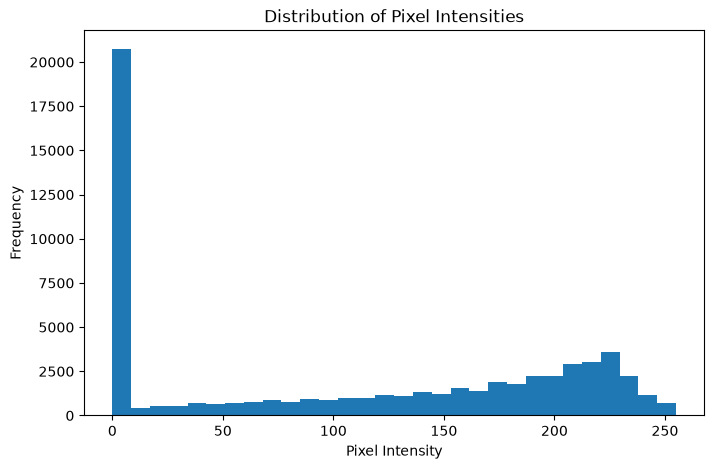

In [23]:
pixel_sample = train_spark.select("pixel_100").toPandas()

plt.figure(figsize=(8, 5))

plt.hist(
    pixel_sample["pixel_100"],
    bins=30
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Distribution of Pixel Intensities")

plt.show()

Normalising the image data

In [24]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [25]:
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

Minimum: 0.0
Maximum: 1.0


Feature Selection

Calculating pixel variance using Spark

In [26]:
pixel_variance = train_spark.select([
    F.variance(F.col(c)).alias(c)
    for c in pixel_columns
])

In [27]:
variance_pd = pixel_variance.toPandas().T.reset_index()

variance_pd.columns = ["pixel", "variance"]

variance_pd["pixel_number"] = (
    variance_pd["pixel"]
    .str.replace("pixel_", "")
    .astype(int)
)

variance_pd = variance_pd.sort_values(
    "variance",
    ascending=False
)

variance_pd.head(20)

,pixel,variance,pixel_number
43,pixel_43,10744.276444,43
40,pixel_40,10735.168208,40
41,pixel_41,10556.901223,41
42,pixel_42,10462.376793,42
740,pixel_740,10316.919380,740
44,pixel_44,10302.203211,44
739,pixel_739,10225.690398,739
744,pixel_744,10199.327585,744
39,pixel_39,9975.384144,39
745,pixel_745,9974.335241,745


Visualise pixel variance

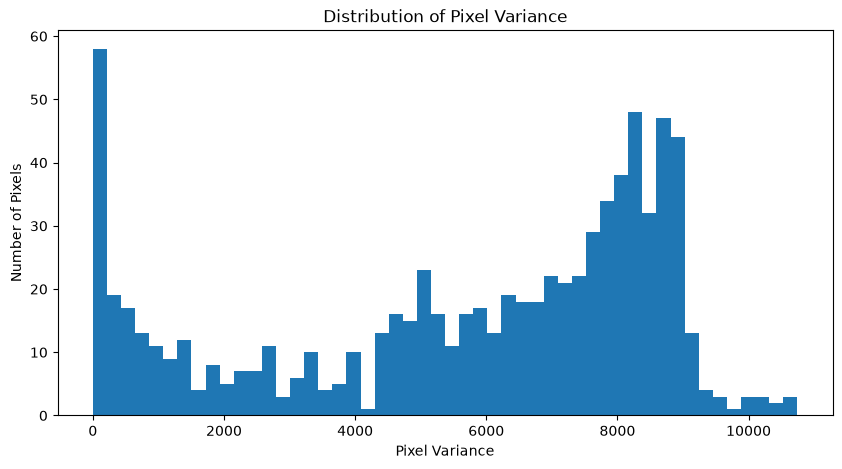

In [28]:
plt.figure(figsize=(10, 5))

plt.hist(
    variance_pd["variance"],
    bins=50
)

plt.xlabel("Pixel Variance")
plt.ylabel("Number of Pixels")
plt.title("Distribution of Pixel Variance")

plt.show()

Selecting informative pixels

In [29]:
n_features = 784

n_selected = int(n_features * 0.95)

selected_pixels = (
    variance_pd
    .head(n_selected)["pixel_number"]
    .values
)

selected_pixels = np.sort(selected_pixels)

print("Original number of pixels:", 784)
print("Selected pixels:", len(selected_pixels))

Original number of pixels: 784
Selected pixels: 744


Creating a feature-selection mask

In [30]:
feature_mask = np.zeros(784, dtype=np.float32)

feature_mask[selected_pixels] = 1

Reshaping it into an image

In [31]:
feature_mask_image = feature_mask.reshape(28, 28)

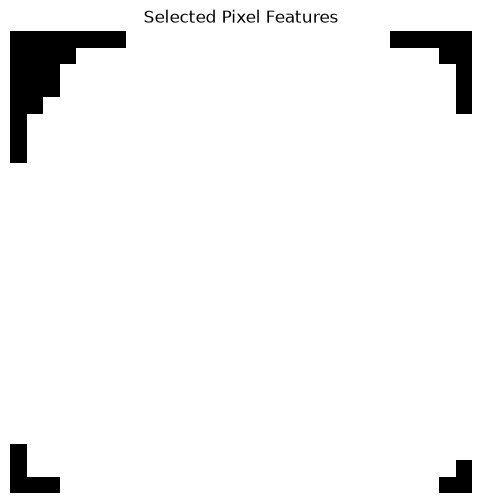

In [32]:
plt.figure(figsize=(6, 6))

plt.imshow(feature_mask_image, cmap="gray")
plt.title("Selected Pixel Features")
plt.axis("off")

plt.show()

Applying the feature-selection mask

In [33]:
X_train_selected = X_train * feature_mask.reshape(1, 28, 28)

X_test_selected = X_test * feature_mask.reshape(1, 28, 28)

In [34]:
print(X_train_selected.shape)
print(X_test_selected.shape)

(60000, 28, 28)
(10000, 28, 28)


Comparing original and selected images

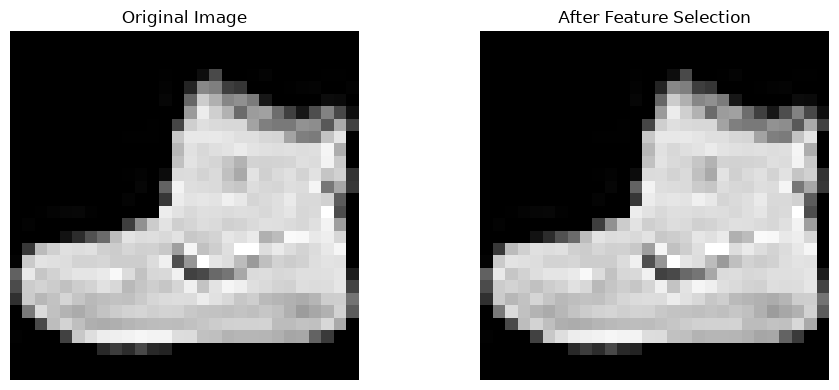

In [35]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_train[0], cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(X_train_selected[0], cmap="gray")
plt.title("After Feature Selection")
plt.axis("off")

plt.tight_layout()
plt.show()

Preparing the data for CNN

In [36]:
X_train_cnn = X_train_selected.reshape(
    X_train_selected.shape[0],
    28,
    28,
    1
)

X_test_cnn = X_test_selected.reshape(
    X_test_selected.shape[0],
    28,
    28,
    1
)

print(X_train_cnn.shape)
print(X_test_cnn.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


Creating training and validation datasets

In [37]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_cnn,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

In [38]:
print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_cnn.shape)

Training: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test: (10000, 28, 28, 1)


Training the CNN

Model 1 — Initial CNN

In [39]:
model = Sequential([
    
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(28, 28, 1)
    ),
    
    MaxPooling2D((2, 2)),
    
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    
    MaxPooling2D((2, 2)),
    
    Flatten(),
    
    Dense(
        128,
        activation="relu"
    ),
    
    Dropout(0.5),
    
    Dense(
        10,
        activation="softmax"
    )
])

C:\Users\nxuma\anaconda3\envs\spark\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Compiling the model

In [41]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Training the model

In [42]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 49ms/step - accuracy: 0.7547 - loss: 0.6812 - val_accuracy: 0.8550 - val_loss: 0.4084
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - accuracy: 0.8380 - loss: 0.4475 - val_accuracy: 0.8733 - val_loss: 0.3492
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.8599 - loss: 0.3857 - val_accuracy: 0.8898 - val_loss: 0.3052
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.8730 - loss: 0.3527 - val_accuracy: 0.8973 - val_loss: 0.2850
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - accuracy: 0.8818 - loss: 0.3253 - val_accuracy: 0.8985 - val_loss: 0.2754
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.8888 - loss: 0.3067 - val_accuracy: 0.9052 - val_loss: 0.2632
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 41ms/step - accuracy: 0.8943 - loss: 0.2870 - val_accuracy: 0.9040 - val_loss: 0.2592
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 49ms/step - accuracy: 0.9005 - loss: 0.2729 - 

Plot training and validation accuracy

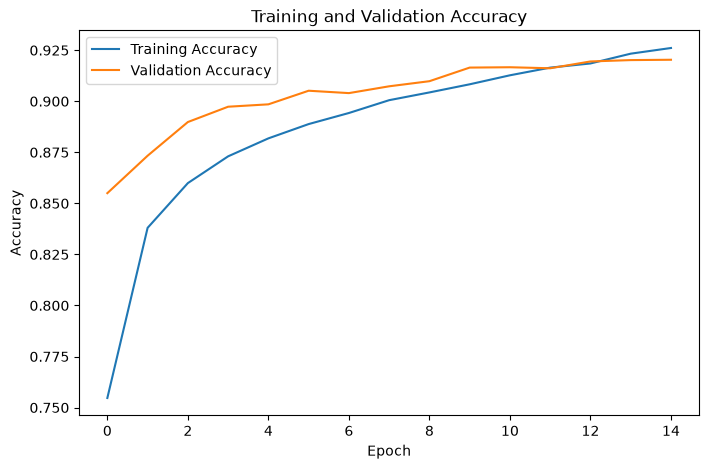

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

Plot training and validation loss

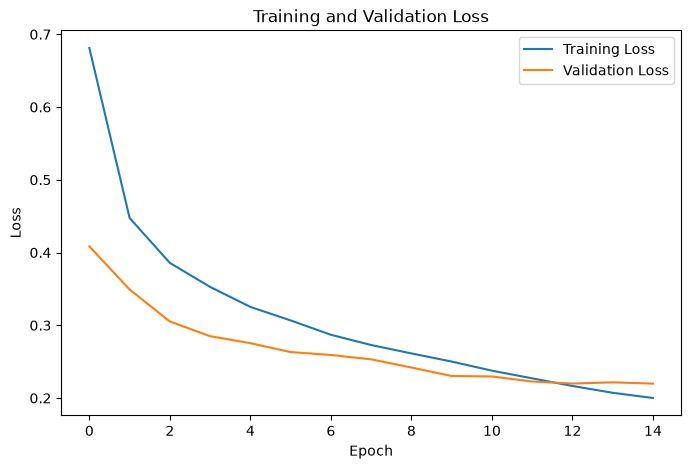

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

Evaluating the model using the test dataset

In [46]:
test_loss, test_accuracy = model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.24631164968013763
Test Accuracy: 0.9107999801635742


Generating predictions

In [48]:
y_pred_prob = model.predict(
    X_test_cnn,
    verbose=0
)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

Classification report

In [49]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.83      0.88      0.86      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.88      0.86      0.87      1000
       Dress       0.91      0.92      0.91      1000
        Coat       0.85      0.88      0.86      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.76      0.71      0.73      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



Confusion matrix

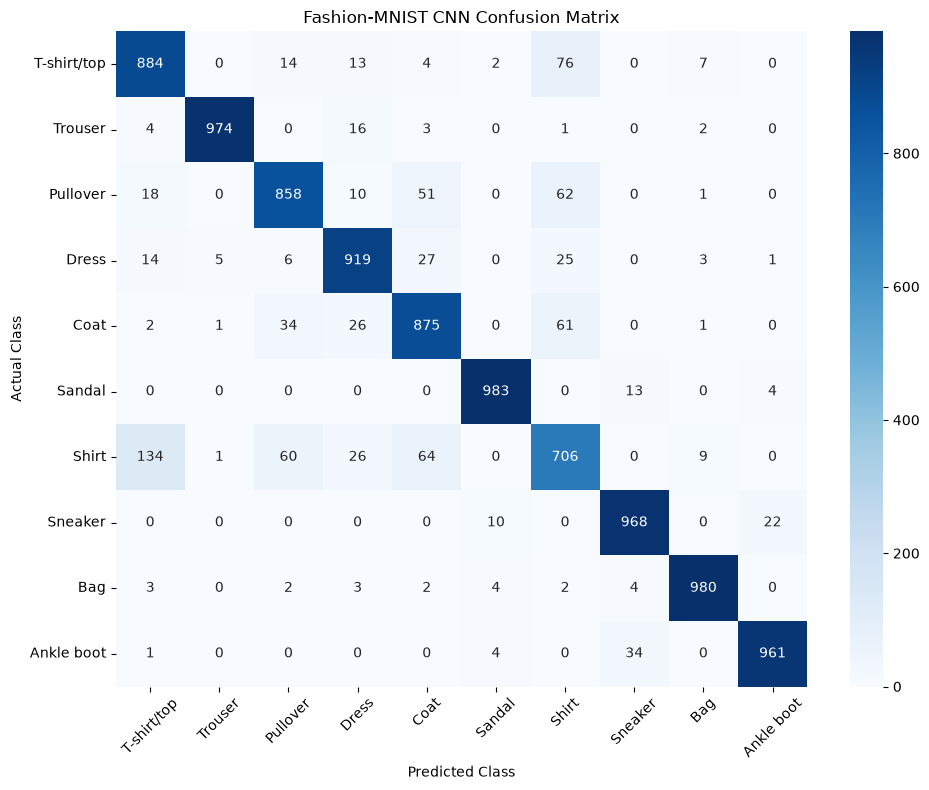

In [50]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Fashion-MNIST CNN Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Using Spark to analyse the model predictions

Creating a Spark DataFrame containing actual and predicted classes

In [51]:
results_pd = pd.DataFrame({
    "actual": y_test,
    "prediction": y_pred
})

results_spark = spark.createDataFrame(results_pd)

results_spark.show(10)

+------+----------+
|actual|prediction|
+------+----------+
|     9|         9|
|     2|         2|
|     1|         1|
|     1|         1|
|     6|         6|
|     1|         1|
|     4|         4|
|     6|         6|
|     5|         5|
|     7|         7|
+------+----------+
only showing top 10 rows



Calculating correct and incorrect predictions

In [52]:
results_spark = results_spark.withColumn(
    "correct",
    F.when(
        F.col("actual") == F.col("prediction"),
        1
    ).otherwise(0)
)

Overall accuracy using Spark

In [54]:
spark_accuracy = results_spark.select(
    F.avg("correct").alias("accuracy")
)

spark_accuracy.show()

+--------+
|accuracy|
+--------+
|  0.9108|
+--------+



Analysing errors by class using Spark

In [55]:
class_errors = results_spark.groupBy("actual") \
    .agg(
        F.count("*").alias("total"),
        F.sum(
            F.when(
                F.col("actual") != F.col("prediction"),
                1
            ).otherwise(0)
        ).alias("errors")
    ) \
    .withColumn(
        "error_rate",
        F.col("errors") / F.col("total")
    ) \
    .orderBy(
        F.col("error_rate").desc()
    )

class_errors.show()

+------+-----+------+----------+
|actual|total|errors|error_rate|
+------+-----+------+----------+
|     6| 1000|   294|     0.294|
|     2| 1000|   142|     0.142|
|     4| 1000|   125|     0.125|
|     0| 1000|   116|     0.116|
|     3| 1000|    81|     0.081|
|     9| 1000|    39|     0.039|
|     7| 1000|    32|     0.032|
|     1| 1000|    26|     0.026|
|     8| 1000|    20|      0.02|
|     5| 1000|    17|     0.017|
+------+-----+------+----------+



Retraining the CNN with improved parameters

In [56]:
from tensorflow.keras.layers import BatchNormalization

Creating Model 2

In [64]:
X_train_cnn = X_train.reshape(
    X_train.shape[0],
    28,
    28,
    1
)

X_test_cnn = X_test.reshape(
    X_test.shape[0],
    28,
    28,
    1
)

print("Training data:", X_train_cnn.shape)
print("Test data:", X_test_cnn.shape)

Training data: (60000, 28, 28, 1)
Test data: (10000, 28, 28, 1)


Creating training and validation sets

In [65]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_cnn,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_cnn.shape)

Training: (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test: (10000, 28, 28, 1)


Data augmentation

In [67]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    height_shift_range=0.08
)

datagen.fit(X_train_final)

Building the improved CNN

In [68]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Dropout,
    Flatten,
    Dense
)

model2 = Sequential([

    Input(shape=(28, 28, 1)),

    # Convolutional Block 1
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling2D((2, 2)),

    Dropout(0.20),


    # Convolutional Block 2
    Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling2D((2, 2)),

    Dropout(0.30),


    # Convolutional Block 3
    Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    BatchNormalization(),

    MaxPooling2D((2, 2)),

    Dropout(0.30),


    # Classification section
    Flatten(),

    Dense(
        128,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(0.40),

    Dense(
        10,
        activation="softmax"
    )
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289,514 (1.10 MB)

 Trainable params: 288,618 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

Compiling the model

In [69]:
from tensorflow.keras.optimizers import Adam

optimizer = Adam(
    learning_rate=0.001
)

model2.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Early Stopping and Learning-Rate Reduction

In [70]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

early_stopping2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

Training the improved Model 2

In [ ]:
history2 = model2.fit(
    datagen.flow(
        X_train_final,
        y_train_final,
        batch_size=128
    ),

    validation_data=(
        X_val,
        y_val
    ),

    epochs=30,

    callbacks=[
        early_stopping2,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 177s 382ms/step - accuracy: 0.7465 - loss: 0.6998 - val_accuracy: 0.5073 - val_loss: 1.8140 - learning_rate: 0.0010
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 153s 362ms/step - accuracy: 0.8341 - loss: 0.4491 - val_accuracy: 0.8910 - val_loss: 0.2906 - learning_rate: 0.0010
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 148s 350ms/step - accuracy: 0.8582 - loss: 0.3896 - val_accuracy: 0.8960 - val_loss: 0.2850 - learning_rate: 0.0010
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 140s 331ms/step - accuracy: 0.8703 - loss: 0.3536 - val_accuracy: 0.8953 - val_loss: 0.2790 - learning_rate: 0.0010
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 138s 326ms/step - accuracy: 0.8793 - loss: 0.3299 - val_accuracy: 0.9153 - val_loss: 0.2283 - learning_rate: 0.0010
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 143s 340ms/step - accuracy: 0.8845 - loss: 0.3179 - val_accuracy: 0.9157 - val_loss: 0.2387 - learning_rate: 0.0010
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 336ms/step - accura

Plot training and validation accuracy

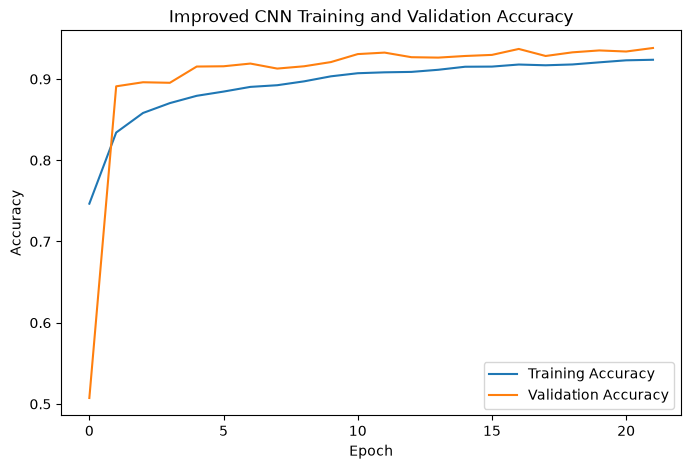

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    history2.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history2.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN Training and Validation Accuracy")

plt.legend()
plt.show()

Plotting Training and Validation loss 

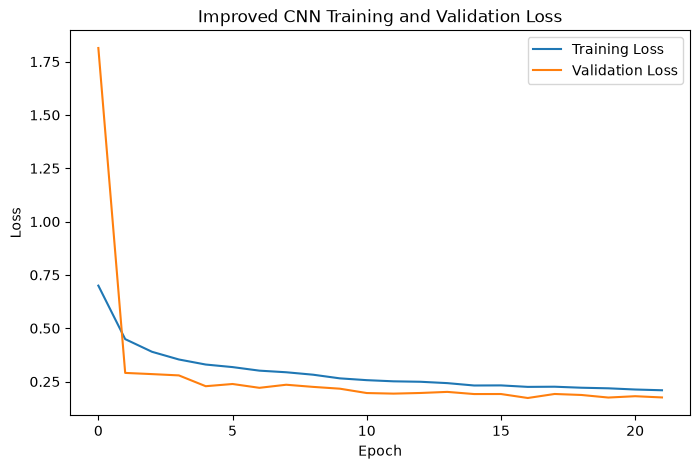

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    history2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN Training and Validation Loss")

plt.legend()
plt.show()

Evaluating the new Model 2

In [74]:
test_loss2, test_accuracy2 = model2.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("Model 2 Test Loss:", test_loss2)
print("Model 2 Test Accuracy:", test_accuracy2)
print(
    "Model 2 Test Accuracy:",
    round(test_accuracy2 * 100, 2),
    "%"
)

Model 2 Test Loss: 0.19829827547073364
Model 2 Test Accuracy: 0.9262999892234802
Model 2 Test Accuracy: 92.63 %


Generating predictions for Model 2

In [77]:
y_pred2_prob = model2.predict(
    X_test_cnn,
    verbose=0
)

y_pred2 = np.argmax(
    y_pred2_prob,
    axis=1
)

Classification report for Model 2

In [78]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred2,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.91      0.84      0.87      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.91      0.90      0.91      1000
       Dress       0.93      0.92      0.93      1000
        Coat       0.89      0.89      0.89      1000
      Sandal       0.99      0.98      0.99      1000
       Shirt       0.74      0.81      0.77      1000
     Sneaker       0.95      0.98      0.97      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.99      0.95      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



Confusion matrix

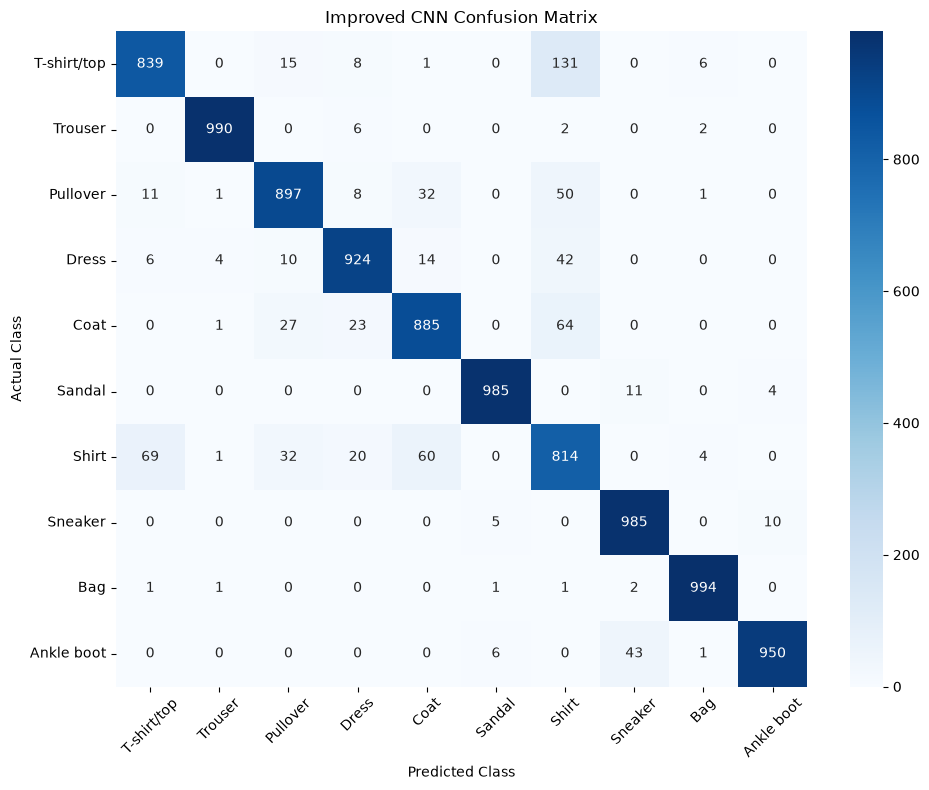

In [79]:
from sklearn.metrics import confusion_matrix

cm2 = confusion_matrix(
    y_test,
    y_pred2
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Improved CNN Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Analysing Model 2 using Spark

In [80]:
results2_pd = pd.DataFrame({
    "actual": y_test,
    "prediction": y_pred2
})

results2_spark = spark.createDataFrame(
    results2_pd
)

results2_spark.show(10)

+------+----------+
|actual|prediction|
+------+----------+
|     9|         9|
|     2|         2|
|     1|         1|
|     1|         1|
|     6|         6|
|     1|         1|
|     4|         4|
|     6|         6|
|     5|         5|
|     7|         7|
+------+----------+
only showing top 10 rows



Calculating Model 2 accuracy using Spark

In [81]:
results2_spark = results2_spark.withColumn(
    "correct",
    F.when(
        F.col("actual") == F.col("prediction"),
        1
    ).otherwise(0)
)

results2_spark.select(
    F.avg("correct").alias("model2_accuracy")
).show()

+---------------+
|model2_accuracy|
+---------------+
|         0.9263|
+---------------+



Analysing errors using Spark

In [82]:
class_errors2 = results2_spark.groupBy("actual") \
    .agg(
        F.count("*").alias("total"),
        F.sum(
            F.when(
                F.col("actual") != F.col("prediction"),
                1
            ).otherwise(0)
        ).alias("errors")
    ) \
    .withColumn(
        "error_rate",
        F.col("errors") / F.col("total")
    ) \
    .orderBy(
        F.col("error_rate").desc()
    )

class_errors2.show()

+------+-----+------+----------+
|actual|total|errors|error_rate|
+------+-----+------+----------+
|     6| 1000|   186|     0.186|
|     0| 1000|   161|     0.161|
|     4| 1000|   115|     0.115|
|     2| 1000|   103|     0.103|
|     3| 1000|    76|     0.076|
|     9| 1000|    50|      0.05|
|     7| 1000|    15|     0.015|
|     5| 1000|    15|     0.015|
|     1| 1000|    10|      0.01|
|     8| 1000|     6|     0.006|
+------+-----+------+----------+



Comparing Model 1 and Model 2

In [83]:
comparison = pd.DataFrame({
    "Model": [
        "CNN Model 1",
        "Improved CNN Model 2"
    ],

    "Test Accuracy": [
        test_accuracy,
        test_accuracy2
    ],

    "Test Loss": [
        test_loss,
        test_loss2
    ]
})

comparison["Test Accuracy (%)"] = (
    comparison["Test Accuracy"] * 100
)

comparison

,Model,Test Accuracy,Test Loss,Test Accuracy (%)
0,CNN Model 1,0.9108,0.246312,91.079998
1,Improved CNN Model 2,0.9263,0.198298,92.629999


Comparison of CNN Model Test Accuracy

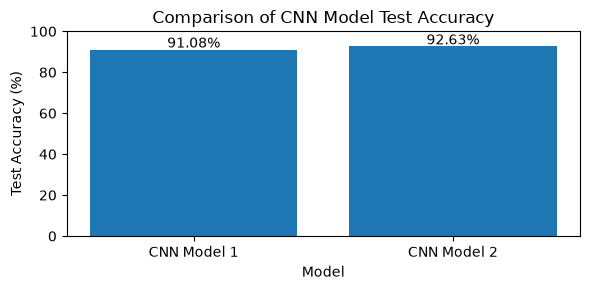

In [86]:

models = [
    "CNN Model 1",
    "CNN Model 2"
]

accuracies = [
    91.08,
    92.63
]

plt.figure(figsize=(6, 3))

bars = plt.bar(
    models,
    accuracies
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Comparison of CNN Model Test Accuracy")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()